## XIC-level quantification

After the optimal XIC is identified for a precursor, the next step is to quantify all XICs of a precursor. We will continue using the example we showed at the "02_get_optimal_xic" step to illustrate the process.

In [1]:
import numpy as np
from jumplion.elution_peaks import extract_ms1_ms2_from_xic_file, smooth

# extract XIC data for a precursor
precursor_id = "MGELASESQGSK2"
xic_file = "../tests/H7_3_S1-E5_1_667.xic_toy.parquet"
ms1_df, ms2_df, ms1_i_df = extract_ms1_ms2_from_xic_file(xic_file, precursor_id)

ms1 = ms1_df.drop(columns=['ms1_rt']).values
ms1_i = ms1_i_df.drop(columns=['ms2_rt']).values
ms2 = ms2_df.drop(columns=['ms2_rt']).values

### 1. Determine the XIC boundaries for quantification
The XIC boundaries are determined based on the peak apex and peak width (FWHM) of the optimal XIC that we calculated from previous step.

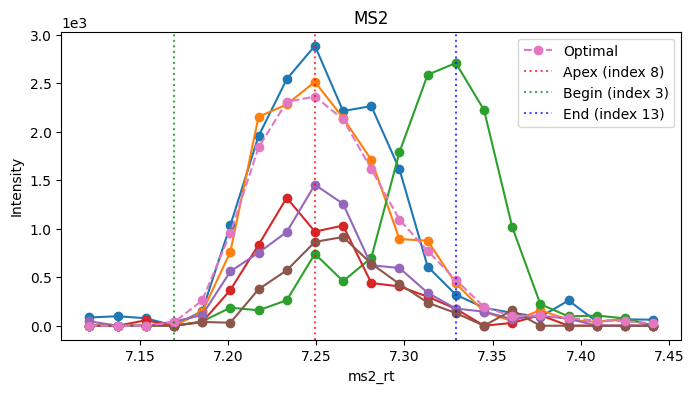

In [2]:
optimal_xic_type = 2
optimal_xic = 1
apex = 8
fwhm = 5

begin = max(0, int(apex - fwhm))
end = min(ms2.shape[0] - 1, int(apex + fwhm))
len_ = end - begin + 1

if optimal_xic_type == 1:
    elution = smooth(ms1[:, optimal_xic])
elif optimal_xic_type == 2:
    elution = smooth(ms2[:, optimal_xic])
    optimal_xic = optimal_xic + ms1.shape[1]
elif optimal_xic_type == 0:
    elution_middle = gaussian_curve(len_, -1, len_//3, np.max(ms2[begin:end+1, :]))
    elution = np.concatenate((np.zeros(begin), 
                              elution_middle, 
                              np.zeros(ms2.shape[0] - end - 1)), 
                              axis=0)

ax = ms2_df.plot(x='ms2_rt', kind='line', marker='o', ylabel='Intensity', figsize=(8,4))
for line in ax.get_lines():
    line.set_label('_nolegend_')
ax.plot(ms2_df['ms2_rt'], elution, marker='o', linestyle='--', label='Optimal')
ax.axvline(x=ms2_df['ms2_rt'][apex], color='red', linestyle=':', alpha=0.7, label=f'Apex (index {apex})')
ax.axvline(x=ms2_df['ms2_rt'][begin], color='green', linestyle=':', alpha=0.7, label=f'Begin (index {begin})')
ax.axvline(x=ms2_df['ms2_rt'][end], color='blue', linestyle=':', alpha=0.7, label=f'End (index {end})')

ax.ticklabel_format(style='sci', axis='y', scilimits=(0, 3), useOffset=True)
ax.set_title("MS2")
ax.legend()

### 2. Calculate the initial quantity for each XIC

In [3]:
from jumplion.elution_peaks import corr

ms1_ms2 = np.concatenate((ms1_i, ms2), axis=1)
n_ms1 = ms1_i.shape[1]
p = ms1_ms2.shape[1]

# Initialize variables
quant_corr = np.zeros((p, 2), dtype=np.float64)
quant_quantity = np.zeros((p, 2), dtype=np.float64)
ms1_ms2_filtered = ms1_ms2.copy()

# Compute total intensity for each fragment and precursor
corr_method=0
quant_corr[:, 0] = np.array([corr(elution[begin:end+1], ms1_ms2[begin:end+1, ion], corr_method) for ion in range(p)])
quant_quantity[:, 0] = np.sum(ms1_ms2[begin:end+1, :], axis=0)

In [4]:
quant_quantity

array([[57090.26636891,     0.        ],
       [33092.7082537 ,     0.        ],
       [14928.4438853 ,     0.        ],
       [    0.        ,     0.        ],
       [    0.        ,     0.        ],
       [15581.        ,     0.        ],
       [13903.        ,     0.        ],
       [ 9630.        ,     0.        ],
       [ 5876.        ,     0.        ],
       [ 6873.        ,     0.        ],
       [ 4232.        ,     0.        ]])

In [5]:
quant_corr

array([[ 0.84884188,  0.        ],
       [ 0.9502008 ,  0.        ],
       [ 0.9756994 ,  0.        ],
       [ 0.        ,  0.        ],
       [ 0.        ,  0.        ],
       [ 0.97461779,  0.        ],
       [ 0.98889622,  0.        ],
       [-0.23042281,  0.        ],
       [ 0.95495138,  0.        ],
       [ 0.94617651,  0.        ],
       [ 0.88891966,  0.        ]])

### 3. Interference removal

In [6]:
# Related parameters
intf_removal = 1
intf_factor_ms1 = 1.2
intf_factor_ms2 = 1.5
E = 0.000000001

# Initialize filtered values
quant_quantity[:, 1] = quant_quantity[:, 0] 
quant_corr[:, 1] = quant_corr[:, 0]

# Apply interference removal
if optimal_xic_type != 0:
    for ion in range(p):
        if ion == optimal_xic:
            continue
        if intf_removal:
            w = max(E, np.sum(elution[apex - 1:apex + 2] ** 2))
            scaled = np.sum(ms1_ms2[apex - 1:apex + 2, :] * elution[apex - 1:apex + 2, None] ** 2, axis=0) / w
            if scaled[optimal_xic]:
                # Compute ratio r
                r = scaled[ion] / scaled[optimal_xic]
    
                # Adjust ratio if correlation is below 0.8
                if quant_corr[ion, 0] < 0.8:
                    # initial r
                    r = min(r, ms1_ms2[apex, ion] / max(E, ms1_ms2[apex, optimal_xic]))
                    # adjust r
                    radj = r
                    e = elution[apex] * 0.5
                    for pos in range(apex - 1, -1, -1): # for the left side of apex point
                        if elution[pos] < e:
                            break
                        radj = min(radj, ms1_ms2[pos, ion] / max(E, ms1_ms2[pos, optimal_xic]))
                    for pos in range(apex + 1, ms1_ms2.shape[0]): # for the right side of apex point
                        if elution[pos] < e:
                            break
                        radj = min(radj, ms1_ms2[pos, ion] / max(E, ms1_ms2[pos, optimal_xic]))
                    # final r
                    r = max(r * 0.5, min(r, radj))
    
                # Apply interference filtering
                if ion < n_ms1: # for MS1 XICs
                    ms1_ms2_filtered[begin:end+1, ion] = np.minimum(ms1_ms2[begin:end+1, ion], intf_factor_ms1 * r * elution[begin:end+1])
                else:           # for MS2 XICs
                    ms1_ms2_filtered[begin:end+1, ion] = np.minimum(ms1_ms2[begin:end+1, ion], intf_factor_ms2 * r * elution[begin:end+1])
                quant_quantity[ion, 1] = np.sum(ms1_ms2_filtered[begin:end+1, ion])

    quant_corr[:, 1] = np.array([corr(elution[begin:end+1], ms1_ms2_filtered[begin:end+1, ion], corr_method) for ion in range(p)])

In [7]:
quant_quantity

array([[57090.26636891, 48733.5051476 ],
       [33092.7082537 , 30813.85121069],
       [14928.4438853 , 14469.38450183],
       [    0.        ,     0.        ],
       [    0.        ,     0.        ],
       [15581.        , 15581.        ],
       [13903.        , 13903.        ],
       [ 9630.        ,  1957.08788784],
       [ 5876.        ,  5876.        ],
       [ 6873.        ,  6858.72862722],
       [ 4232.        ,  4232.        ]])

In [8]:
quant_corr

array([[ 0.84884188,  0.98983197],
       [ 0.9502008 ,  0.98733135],
       [ 0.9756994 ,  0.98588803],
       [ 0.        ,  0.        ],
       [ 0.        ,  0.        ],
       [ 0.97461779,  0.97461779],
       [ 0.98889622,  0.98889622],
       [-0.23042281,  0.93214715],
       [ 0.95495138,  0.95495138],
       [ 0.94617651,  0.94694851],
       [ 0.88891966,  0.88891966]])

In [12]:
import pandas as pd
pd.DataFrame(ms1_ms2_filtered)

,0,1,2,3,4,5,6,7,8,9,10
0,47.984964,55.658940,47.677109,0.0,0.0,85.0,0.0,0.000000,0.0,45.000000,0.0
1,24.014317,64.667661,26.334725,0.0,0.0,98.0,0.0,0.000000,0.0,0.000000,0.0
2,15.994033,60.334328,79.979116,0.0,0.0,77.0,0.0,0.000000,56.0,0.000000,0.0
3,35.994632,89.931899,41.545225,0.0,0.0,0.0,0.0,0.000000,0.0,27.728627,0.0
4,392.562034,354.273259,169.956436,0.0,0.0,151.0,140.0,41.418035,37.0,110.000000,39.0
5,3285.652784,1880.468196,1080.687481,0.0,0.0,1036.0,761.0,151.786554,368.0,560.000000,31.0
6,6048.248098,3588.369849,1698.607383,0.0,0.0,1953.0,2153.0,159.000000,833.0,752.000000,376.0
7,7763.274224,4852.784110,2192.384182,0.0,0.0,2540.0,2280.0,262.000000,1318.0,966.000000,570.0
8,7997.731905,5316.980906,2319.350200,0.0,0.0,2885.0,2513.0,375.865683,970.0,1453.000000,864.0
9,7410.796982,4697.679012,2397.216735,0.0,0.0,2212.0,2141.0,338.386539,1032.0,1256.000000,914.0


In [13]:
ms1_i_df_adj

,ms2_rt,612.2823,612.784,613.2856,613.7873,614.289
0,7.121352,47.984964,55.658940,47.677109,0.0,0.0
1,7.137338,24.014317,64.667661,26.334725,0.0,0.0
2,7.153321,15.994033,60.334328,79.979116,0.0,0.0
3,7.169307,35.994632,89.931899,41.545225,0.0,0.0
4,7.185292,392.562034,354.273259,169.956436,0.0,0.0
5,7.201273,3285.652784,1880.468196,1080.687481,0.0,0.0
6,7.217254,6048.248098,3588.369849,1698.607383,0.0,0.0
7,7.233235,7763.274224,4852.784110,2192.384182,0.0,0.0
8,7.249225,7997.731905,5316.980906,2319.350200,0.0,0.0
9,7.265204,7410.796982,4697.679012,2397.216735,0.0,0.0


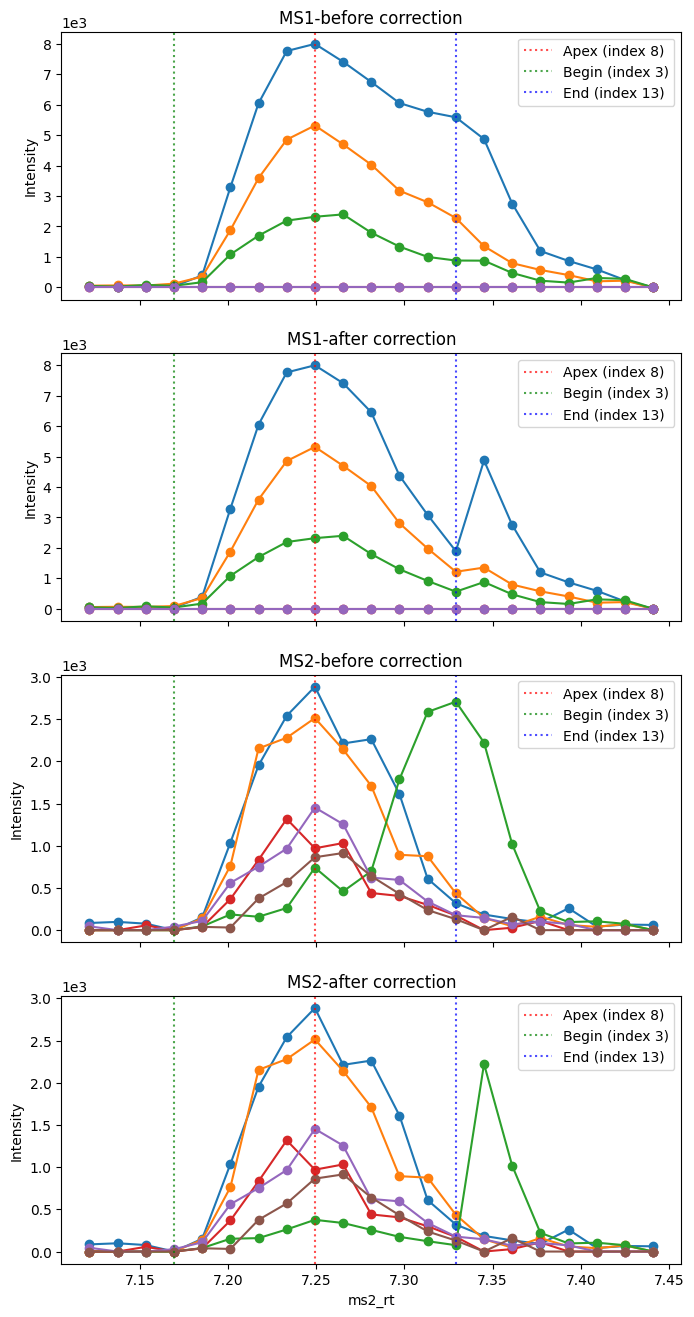

In [14]:
import matplotlib.pyplot as plt

ms1_i_df_adj = ms1_i_df.copy()
ms1_i_df_adj.iloc[:, 1:5] = ms1_ms2_filtered[:, 0:4]
ms2_df_adj = ms2_df.copy()
ms2_df_adj.iloc[:, 1:] = ms1_ms2_filtered[:, 5:]

# Draw plots to show XICs
fig, (ax1, ax2, ax3, ax4) = plt.subplots(4, 1, figsize=(8, 16), sharex=True)
#
ms1_i_df.plot(x='ms2_rt', kind='line', marker='o', ax=ax1, ylabel='Intensity')
ax1.ticklabel_format(style='sci', axis='y', scilimits=(0, 3), useOffset=True)
ax1.set_title("MS1-before correction")
#
ms1_i_df_adj.plot(x='ms2_rt', kind='line', marker='o', ax=ax2, ylabel='Intensity')
ax2.ticklabel_format(style='sci', axis='y', scilimits=(0, 3), useOffset=True)
ax2.set_title("MS1-after correction")
#
ms2_df.plot(x='ms2_rt', kind='line', marker='o', ax=ax3, ylabel='Intensity')
ax3.ticklabel_format(style='sci', axis='y', scilimits=(0, 3), useOffset=True)
ax3.set_title("MS2-before correction")
#
ms2_df_adj.plot(x='ms2_rt', kind='line', marker='o', ax=ax4, ylabel='Intensity')
ax4.ticklabel_format(style='sci', axis='y', scilimits=(0, 3), useOffset=True)
ax4.set_title("MS2-after correction")

for ax in [ax1, ax2, ax3, ax4]:
    for line in ax.get_lines():
        line.set_label('_nolegend_')
    ax.axvline(x=ms2_df['ms2_rt'][apex], color='red', linestyle=':', alpha=0.7, label=f'Apex (index {apex})')
    ax.axvline(x=ms2_df['ms2_rt'][begin], color='green', linestyle=':', alpha=0.7, label=f'Begin (index {begin})')
    ax.axvline(x=ms2_df['ms2_rt'][end], color='blue', linestyle=':', alpha=0.7, label=f'End (index {end})')
    ax.legend()

### Summary
The above analysis can be done with a single function:

In [15]:
from jumplion.elution_peaks import calculate_quantity

(ms1_ms2_filtered, 
 elution, 
 quant_corr, 
 quant_quantity) = calculate_quantity(ms1_i, ms2, 
                                      begin, end, 
                                      apex, 
                                      optimal_xic=1, 
                                      optimal_xic_type=2, 
                                      corr_method=0, 
                                      intf_removal=1, 
                                      intf_factor_ms1=1.2,
                                      intf_factor_ms2=1.5)

In [16]:
quant_quantity

array([[57090.26636891, 48733.5051476 ],
       [33092.7082537 , 30813.85121069],
       [14928.4438853 , 14469.38450183],
       [    0.        ,     0.        ],
       [    0.        ,     0.        ],
       [15581.        , 15581.        ],
       [13903.        , 13903.        ],
       [ 9630.        ,  1957.08788784],
       [ 5876.        ,  5876.        ],
       [ 6873.        ,  6858.72862722],
       [ 4232.        ,  4232.        ]])

In [17]:
quant_corr

array([[ 0.84884188,  0.98983197],
       [ 0.9502008 ,  0.98733135],
       [ 0.9756994 ,  0.98588803],
       [ 0.        ,  0.        ],
       [ 0.        ,  0.        ],
       [ 0.97461779,  0.97461779],
       [ 0.98889622,  0.98889622],
       [-0.23042281,  0.93214715],
       [ 0.95495138,  0.95495138],
       [ 0.94617651,  0.94694851],
       [ 0.88891966,  0.88891966]])